# Portfolio Risk Review — walkthrough
A step-by-step build of the analysis behind `report.png`. Every metric lives in a small, documented function in
`metrics.py` / `optimize.py`, so each step here is just *call it and interpret it*.

**Pipeline:** prices → returns → portfolio returns → risk metrics → optimisation → validation.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import config, data, metrics, optimize, backtest
pd.set_option("display.width", 160)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

prices = data.load_prices()
rets   = data.to_returns(prices)
w_cur  = data.get_current_weights(rets.columns)   # config.WEIGHTS as an array, in column order
port   = data.portfolio_returns(rets, w_cur)
bench  = rets[config.BENCHMARK]
print(config.WEIGHTS); prices.tail(3)

{'SPY': 0.4, 'EFA': 0.15, 'EEM': 0.05, 'AGG': 0.25, 'GLD': 0.1, 'VNQ': 0.05}


,SPY,EFA,EEM,AGG,GLD,VNQ
Date,,,,,,
2025-12-26,684.960022,95.065636,54.516636,97.055496,416.739990,86.402596
2025-12-29,682.519043,94.780151,54.377361,97.171906,398.600006,86.577621
2025-12-30,681.685547,94.937660,54.596222,97.133102,398.890015,86.752647


## 1. Return, volatility and Sharpe
Returns are *simple daily returns*; we annualise with 252 trading days. **Sharpe = (return − risk-free) / volatility**:
how much reward we earn per unit of total risk.

In [2]:
pd.DataFrame({"Portfolio": metrics.summary(port, bench), config.BENCHMARK: metrics.summary(bench)}).round(4)

,Portfolio,SPY
Alpha (ann.),-0.0070,NaN
Ann. return,0.0935,0.1484
Ann. volatility,0.1091,0.1667
Beta,0.6229,NaN
CVaR 95%,0.0159,0.0252
Calmar,0.3973,0.4400
Information ratio,-0.7698,NaN
Kurtosis,20.4752,17.6951
Max DD duration (days),496.0000,488.0000
Max drawdown,-0.2354,-0.3372


## 2. Drawdowns
Drawdown = how far wealth sits below its previous peak. Max drawdown is the worst such fall; the *duration* shows how
long an investor waited to get back to break-even.

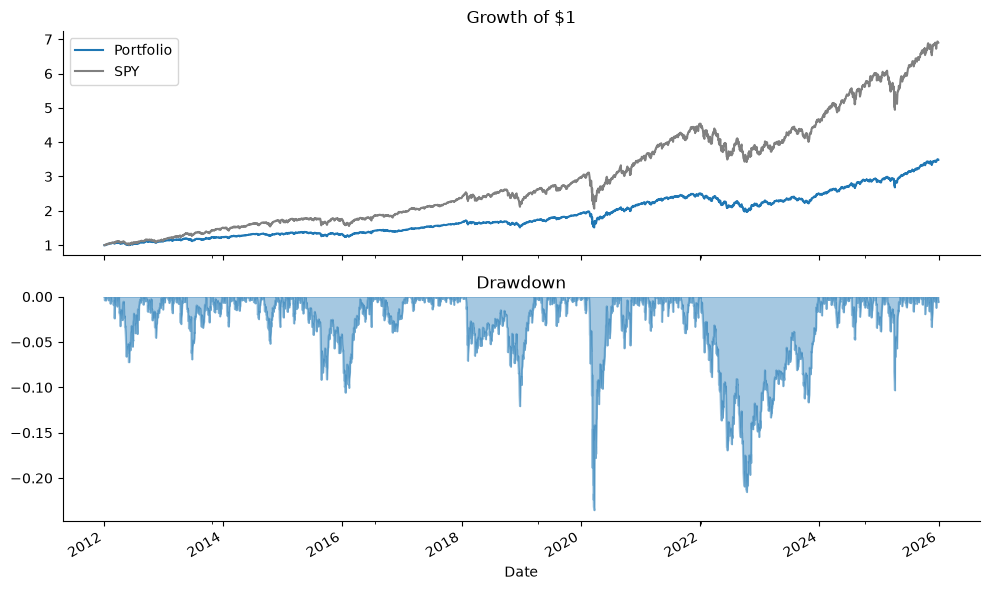

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
metrics.wealth_index(port).plot(ax=ax[0], label="Portfolio"); metrics.wealth_index(bench).plot(ax=ax[0], label="SPY", color="grey")
ax[0].legend(); ax[0].set_title("Growth of $1")
metrics.drawdown_series(port).plot.area(ax=ax[1], alpha=.4); ax[1].set_title("Drawdown"); plt.tight_layout()

## 3. Value-at-Risk and CVaR — three ways
* **Historical VaR**: the 5th-percentile daily return. No assumptions.
* **Gaussian VaR**: assumes returns are normal.
* **Cornish-Fisher VaR**: Gaussian VaR corrected for skewness and kurtosis.
* **CVaR (Expected Shortfall)**: the *average* loss on days worse than VaR — it looks inside the tail.

Our returns have skew < 0 and kurtosis ≫ 3 (fat left tail), which is exactly why the Gaussian assumption is shaky.

In [4]:
pd.Series({
 "Skewness": metrics.skewness(port), "Kurtosis (normal=3)": metrics.kurtosis(port),
 "VaR hist.": metrics.var_historical(port), "VaR Gaussian": metrics.var_gaussian(port),
 "VaR Cornish-Fisher": metrics.var_cornish_fisher(port), "CVaR": metrics.cvar_historical(port)}).round(4)

Skewness               -0.5617
Kurtosis (normal=3)    20.4752
VaR hist.               0.0100
VaR Gaussian            0.0109
VaR Cornish-Fisher      0.0096
CVaR                    0.0159
dtype: float64

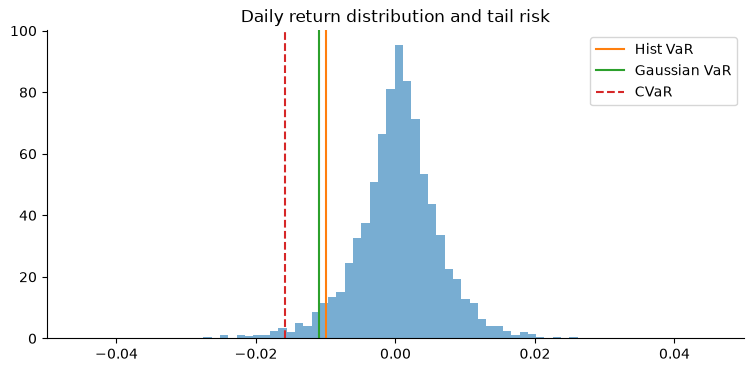

In [5]:
plt.figure(figsize=(9, 4))
plt.hist(port, bins=120, density=True, alpha=.6)
for name, f, c in [("Hist VaR", metrics.var_historical, "C1"), ("Gaussian VaR", metrics.var_gaussian, "C2")]:
    plt.axvline(-f(port), color=c, label=name)
plt.axvline(-metrics.cvar_historical(port), color="C3", ls="--", label="CVaR")
plt.legend(); plt.title("Daily return distribution and tail risk"); plt.xlim(-.05, .05);

## 4. Where does the risk come from?
Risk contribution of asset *i* = $w_i (\Sigma w)_i / w'\Sigma w$. Weights show where money sits; risk contribution shows
where **risk** sits. The equity-like assets (SPY, EFA, EEM, VNQ) are 65% of capital but ~93% of the risk.

In [6]:
mu, cov = optimize.annual_stats(rets)
pd.DataFrame({"Weight": w_cur, "Risk contribution": metrics.risk_contributions(w_cur, cov)}, index=rets.columns).round(3)

,Weight,Risk contribution
SPY,0.40,0.581
EFA,0.15,0.210
EEM,0.05,0.075
AGG,0.25,0.028
GLD,0.10,0.038
VNQ,0.05,0.068


## 5. Efficient frontier, GMV, MSR (and ERC)
* **GMV** — lowest-volatility portfolio (needs only the covariance matrix).
* **MSR** — highest Sharpe ratio; the tangency point where the Capital Market Line touches the frontier.
* **ERC** — risk parity: every asset contributes equal risk.

Solved with `scipy.optimize.minimize` (SLSQP), long-only, fully invested.

In [7]:
portfolios = {
    "Current": w_cur,
    "GMV": optimize.gmv(cov),
    "MSR": optimize.msr(mu, cov),
    "ERC": optimize.erc(cov),
    "Equal weight": np.full(len(mu), 1 / len(mu)),
}
pd.DataFrame(portfolios, index=rets.columns).round(3)

,Current,GMV,MSR,ERC,Equal weight
SPY,0.40,0.062,0.71,0.099,0.167
EFA,0.15,0.000,0.00,0.093,0.167
EEM,0.05,0.000,0.00,0.082,0.167
AGG,0.25,0.938,0.00,0.486,0.167
GLD,0.10,0.000,0.29,0.154,0.167
VNQ,0.05,0.000,0.00,0.086,0.167


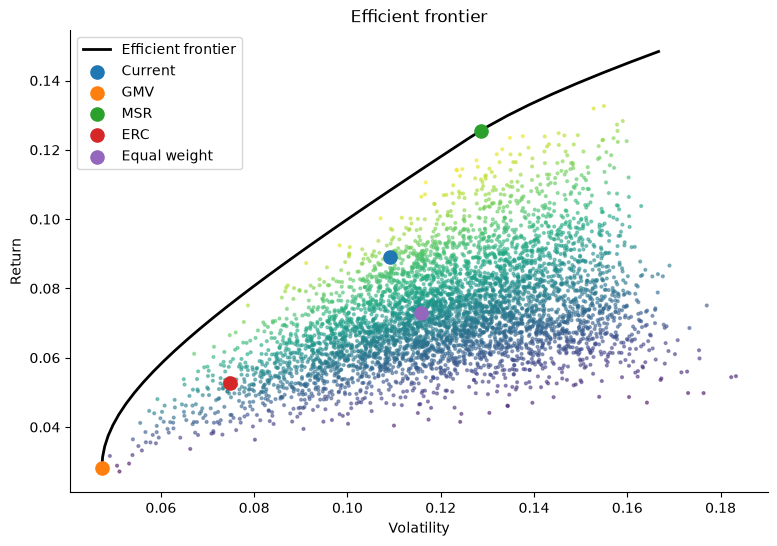

In [8]:
cloud = optimize.random_portfolios(mu, cov); ef = optimize.efficient_frontier(mu, cov)
plt.figure(figsize=(9, 6))
plt.scatter(cloud.vol, cloud.ret, c=cloud.sharpe, s=4, alpha=.5, cmap="viridis")
plt.plot(ef.vol, ef.ret, "k", lw=2, label="Efficient frontier")
for name, w in portfolios.items():
    plt.scatter(optimize.port_vol(w, cov), optimize.port_ret(w, mu), s=90, zorder=5, label=name)
plt.xlabel("Volatility"); plt.ylabel("Return"); plt.legend(); plt.title("Efficient frontier");

## 6. Does optimisation survive out-of-sample?
Fit GMV / MSR / ERC on data **before 2020**, then hold the weights through 2020 onward. Optimisers love assets that
*happened* to do well in the sample (estimation error), so optimal-in-sample rarely means optimal-out-of-sample.

In [9]:
oos = backtest.out_of_sample(rets)
display(oos["weights"].round(2))
oos["table"][["Ann. return", "Ann. volatility", "Sharpe", "Max drawdown"]].round(3)

,SPY,EFA,EEM,AGG,GLD,VNQ
Equal weight,0.17,0.17,0.17,0.17,0.17,0.17
Current,0.40,0.15,0.05,0.25,0.10,0.05
GMV,0.09,0.00,0.00,0.91,0.00,0.00
MSR,0.34,0.00,0.00,0.66,0.00,0.00
ERC,0.09,0.08,0.06,0.59,0.11,0.08


,Ann. return,Ann. volatility,Sharpe,Max drawdown
Equal weight,0.095,0.142,0.527,-0.248
Current,0.105,0.136,0.623,-0.235
GMV,0.024,0.065,0.054,-0.175
MSR,0.061,0.089,0.458,-0.184
ERC,0.057,0.086,0.432,-0.190


## 7. Is the VaR model any good? (rolling backtest)
Each day: estimate 95% VaR from the previous 2 years, then check if today's loss exceeded it. We expect breaches on
~5% of days. The **Kupiec test** p-value > 0.05 means we can't reject correct coverage.

In [10]:
print("95% VaR"); display(backtest.var_backtest(port, level=0.05).round(4))
print("99% VaR"); display(backtest.var_backtest(port, level=0.01).round(4))

95% VaR


,Breaches,Observations,Breach rate,Expected rate,Kupiec p-value
Historical,170.0,3014.0,0.0564,0.05,0.1136
Gaussian,156.0,3014.0,0.0518,0.05,0.6596
Cornish-Fisher,163.0,3014.0,0.0541,0.05,0.3100


99% VaR


,Breaches,Observations,Breach rate,Expected rate,Kupiec p-value
Historical,46.0,3014.0,0.0153,0.01,0.0070
Gaussian,67.0,3014.0,0.0222,0.01,0.0000
Cornish-Fisher,28.0,3014.0,0.0093,0.01,0.6917


At **95%** all three methods pass. Gaussian is even the closest to 5%, because 95% is not far enough into the tail
for the fat tails to matter much. At **99%** the picture flips: Gaussian VaR is breached ~2.2% of days instead of 1%
and fails badly, historical also fails, and only **Cornish-Fisher**, which adjusts for skew and kurtosis, passes.

## 8. Stress periods

In [11]:
backtest.stress_test(rets, w_cur).round(3)

,Portfolio return,Benchmark return,Portfolio max DD
COVID crash,-0.233,-0.334,-0.235
2022 rate hikes,-0.214,-0.238,-0.215


## Take-aways
* Diversification: AGG and GLD have near-zero correlation with equities, which cuts drawdown versus SPY.
* Gaussian VaR understates tail risk in fat-tailed markets; CVaR and Cornish-Fisher give a more honest picture.
* Mean-variance "optimal" portfolios are fragile out-of-sample — a reason to prefer simple/robust rules (equal weight, ERC) or shrinkage.

**Future work:** covariance shrinkage (Ledoit-Wolf), Monte Carlo VaR, factor models, transaction costs.